<a href="https://colab.research.google.com/github/briankinney072-cmd/UPC_DAPR_2026/blob/DAPR-Submissions/S4_Flipped_JeedMarcVillamil_submit_rev1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

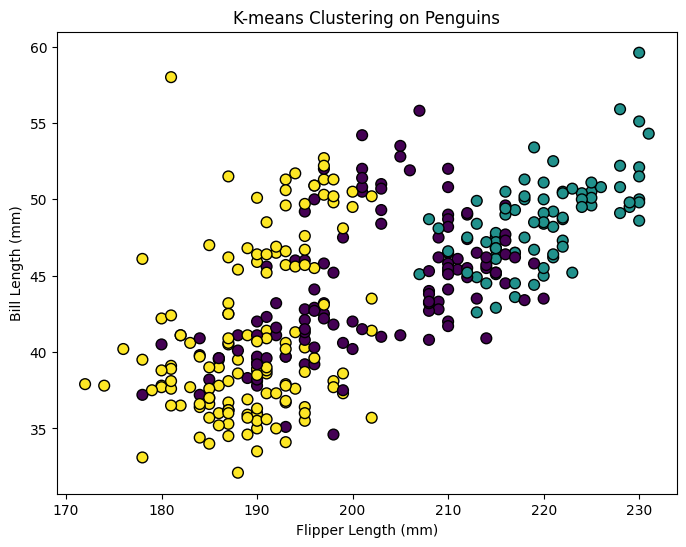

Confusion Matrix (Crosstab):
Cluster        0   1   2
True Species            
Adelie        53   0  98
Chinstrap     22   0  46
Gentoo        42  81   0

Adjusted Rand Score: 0.3100937047458321


In [7]:
"""
Exercise 1 — K-means on the Penguins dataset
--------------------------------------------

This script:
1. Loads the penguins dataset.
2. Selects numeric columns and handles missing values.
3. Applies k-means clustering with 3 clusters.
4. Visualizes the clusters using a scatterplot.
5. Compares clustering results with real species using:
   - Confusion matrix (via pandas crosstab to avoid mixed-type errors)
   - Adjusted Rand Score (ARS)
"""

import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
#start defining the subroutines
def prepare_penguins():
    """
    Loads the penguins dataset, selects numeric columns,
    and removes rows with missing values.

    Returns:
        df (DataFrame): Cleaned dataset with numeric columns + species.
    """
    penguins = sns.load_dataset("penguins")

    numeric_cols = [
        "bill_length_mm",
        "bill_depth_mm",
        "flipper_length_mm",
        "body_mass_g"
    ]

    df = penguins[numeric_cols + ["species"]].dropna()
    return df

def run_kmeans(df, k=3):
    """
    Applies k-means clustering to the numeric columns.

    Args:
        df (DataFrame): Cleaned penguins dataset.
        k (int): Number of clusters.

    Returns:
        labels (ndarray): Cluster labels assigned by k-means.
        model (KMeans): Fitted k-means model.
    """
    X = df.drop(columns=["species"])
    model = KMeans(n_clusters=k, random_state=42)
    labels = model.fit_predict(X)
    return labels, model

def plot_clusters(df, labels):
    """
    Creates a scatterplot of flipper_length vs bill_length,
    colored by k-means cluster labels.

    Args:
        df (DataFrame): Dataset with numeric columns.
        labels (ndarray): Cluster labels.
    """
    plt.figure(figsize=(8, 6))
    plt.scatter(
        df["flipper_length_mm"],
        df["bill_length_mm"],
        c=labels,
        cmap="viridis",
        s=60,
        edgecolor="black"
    )
    plt.xlabel("Flipper Length (mm)")
    plt.ylabel("Bill Length (mm)")
    plt.title("K-means Clustering on Penguins")
    plt.show()

def evaluate(df, labels):
    """
    Computes confusion matrix and Adjusted Rand Score (ARS)
    comparing k-means clusters with real species.

    Args:
        df (DataFrame): Dataset including species.
        labels (ndarray): Cluster labels.

    Prints:
        Confusion matrix (cross-tabulation)
        Adjusted Rand Score
    """
    true_species = df["species"]

    # Using pd.crosstab instead of sklearn's confusion_matrix. provides a clearer, labeled contingency table of species versus clusters and completely avoids the mixed type restriction
    # because the inputs have different types (string vs integer). To fix this without needing manual label-to-integer encoding, we can replace the scikit-learn confusion_matrix with pandas' pd.crosstab(true_species, labels)
    cm = pd.crosstab(true_species, labels, rownames=['True Species'], colnames=['Cluster'])
    ars = adjusted_rand_score(true_species, labels)

    print("Confusion Matrix (Crosstab):")
    print(cm)
    print("\nAdjusted Rand Score:", ars)

# -------------------------
# Run all the defined steps in series according to the task list
# -------------------------

df = prepare_penguins()
labels, model = run_kmeans(df)
plot_clusters(df, labels)
evaluate(df, labels)

Missing values present: False
Custom distance: 5.656854249492381
Numpy distance: 5.656854249492381


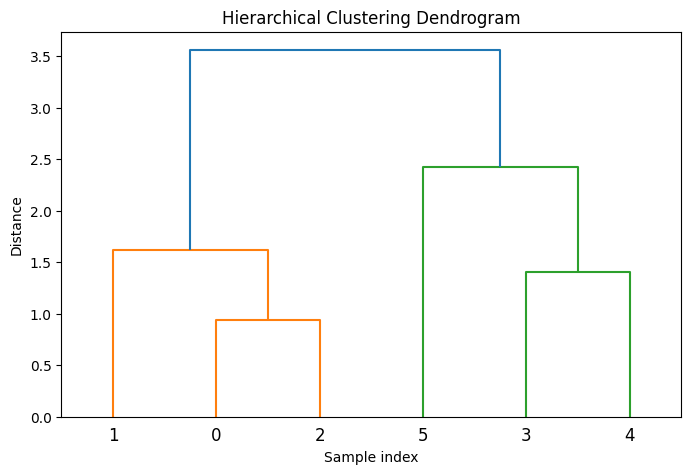

Agglomerative labels: [1 1 1 0 0 0]
K-means labels: [0 0 0 1 1 1]


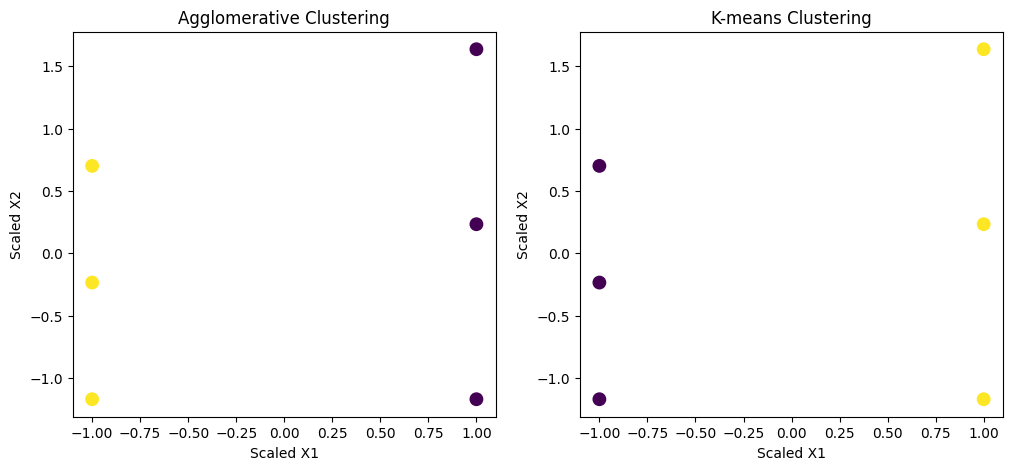

Agglomerative cluster sizes: {np.int64(1): 3, np.int64(0): 3}
K-means cluster sizes: {np.int32(0): 3, np.int32(1): 3}


In [2]:
"""
Exercise 2: Hierarchical clustering + a custom distance function (S1 + S3)
--------------------------------------------
We'll use the small synthetic dataset from the S3 notebook:
This script:
1.  euclidean_distance(p1, p2) without using numpy or sklear
2.  Apply Agglomerative Clustering with n_clusters=2 and plot the dendogram
3. Also apply k-means with n_clusters=2 to the same normalized data.
4. Compare the cluster labels obtained by agglomerative clustering and k-means
5. Write a function cluster_sizes(labels) that takes an array of cluster labels and returns a dictionary with the count of observations per cluste

"""

import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) check for missing values with np.isnan(X).any()
print("Missing values present:", np.isnan(X).any())

# b) normalize X with StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# c) plain-Python euclidean_distance function using a for loop (no numpy/sklearn)
def euclidean_distance(p1, p2):
    """
    Computes Euclidean distance between two points using only
    a for loop (no numpy or sklearn).

    Args:
        p1 (list or tuple): First point.
        p2 (list or tuple): Second point.

    Returns:
        float: Euclidean distance.
    """
    total = 0
    for i in range(len(p1)):
        diff = p1[i] - p2[i]
        total += diff * diff
    return total ** 0.5

# test it
print("Custom distance:", euclidean_distance(X[0], X[3]))
print("Numpy distance:", np.linalg.norm(X[0] - X[3]))

# d) agglomerative clustering on X_scaled + dendrogram
def run_hierarchical(X_scaled):
    """
    Runs Agglomerative Clustering with n_clusters=2 and plots
    the dendrogram using scipy linkage.

    Args:
        X_scaled (ndarray): Normalized dataset.

    Returns:
        labels (ndarray): Cluster labels from AgglomerativeClustering.
    """
    agglo = AgglomerativeClustering(n_clusters=2)
    labels = agglo.fit_predict(X_scaled)

    # linkage matrix for dendrogram
    Z = linkage(X_scaled, method="ward")

    plt.figure(figsize=(8, 5))
    dendrogram(Z)
    plt.title("Hierarchical Clustering Dendrogram")
    plt.xlabel("Sample index")
    plt.ylabel("Distance")
    plt.show()

    return labels

agglo_labels = run_hierarchical(X_scaled)

# e) k-means clustering with n_clusters=2 on X_scaled
def run_kmeans(X_scaled):
    """
    Applies k-means clustering with n_clusters=2.

    Args:
        X_scaled (ndarray): Normalized dataset.

    Returns:
        labels (ndarray): Cluster labels from KMeans.
    """
    model = KMeans(n_clusters=2, random_state=42)
    labels = model.fit_predict(X_scaled)
    return labels

kmeans_labels = run_kmeans(X_scaled)

# f) compare both label arrays and make a side-by-side scatterplot
print("Agglomerative labels:", agglo_labels)
print("K-means labels:", kmeans_labels)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=agglo_labels, cmap="viridis", s=80)
plt.title("Agglomerative Clustering")
plt.xlabel("Scaled X1")
plt.ylabel("Scaled X2")

plt.subplot(1, 2, 2)
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=kmeans_labels, cmap="viridis", s=80)
plt.title("K-means Clustering")
plt.xlabel("Scaled X1")
plt.ylabel("Scaled X2")

plt.show()

# g) cluster_sizes function using a dictionary
def cluster_sizes(labels):
    """
    Counts number of observations per cluster using a dictionary.

    Args:
        labels (ndarray): Cluster labels.

    Returns:
        dict: Mapping cluster_id -> count.
    """
    counts = {}
    for label in labels:
        if label not in counts:
            counts[label] = 1
        else:
            counts[label] += 1
    return counts

print("Agglomerative cluster sizes:", cluster_sizes(agglo_labels))
print("K-means cluster sizes:", cluster_sizes(kmeans_labels))


Missing values per column before dropna():
carat    0
depth    0
table    0
price    0
dtype: int64

Missing values per column after dropna():
carat    0
depth    0
table    0
price    0
dtype: int64


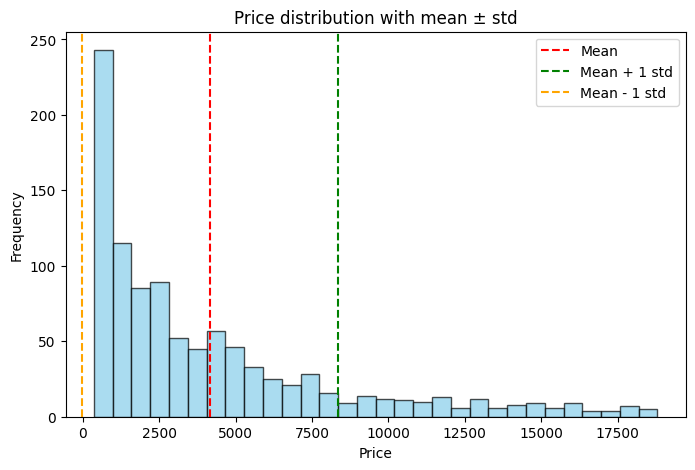

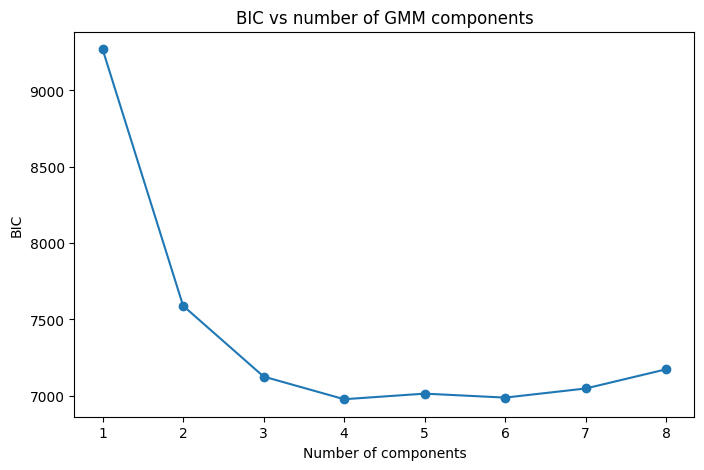

Best number of components according to BIC: 4


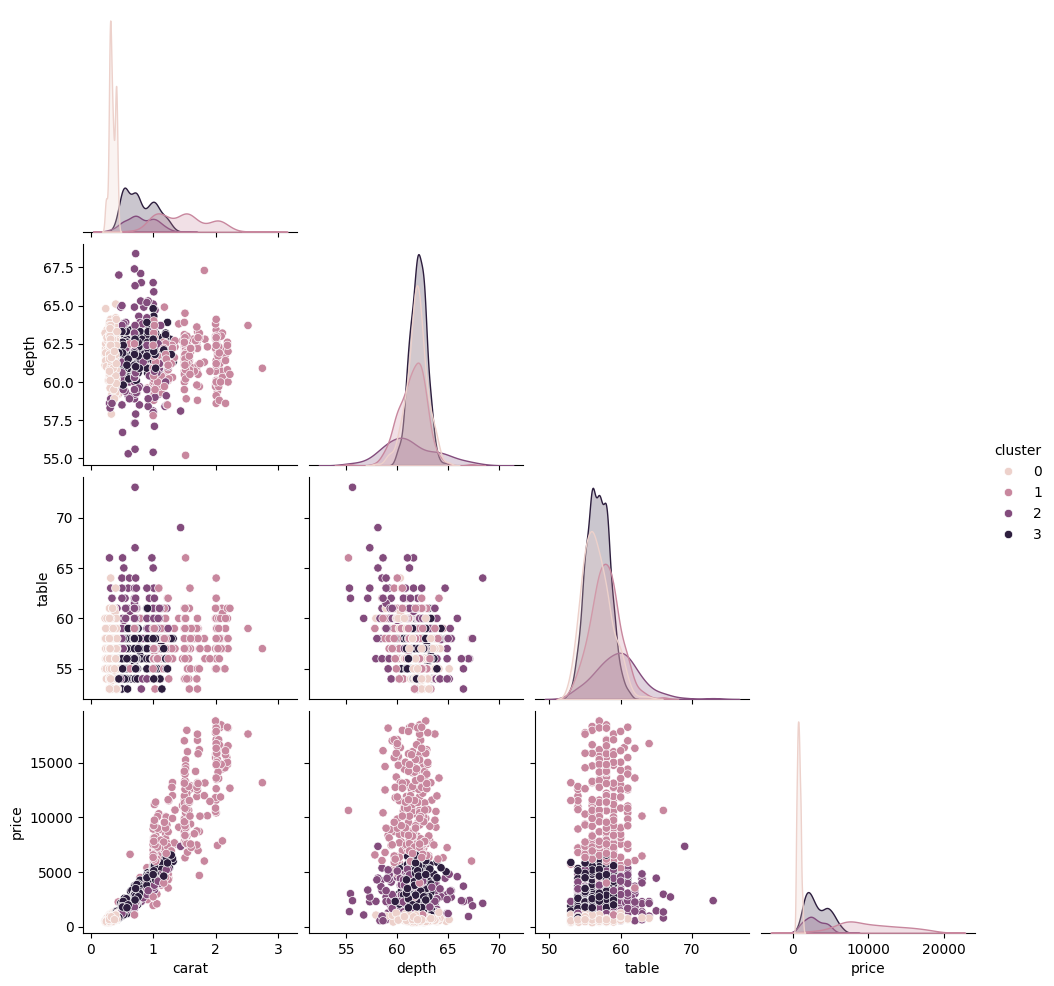

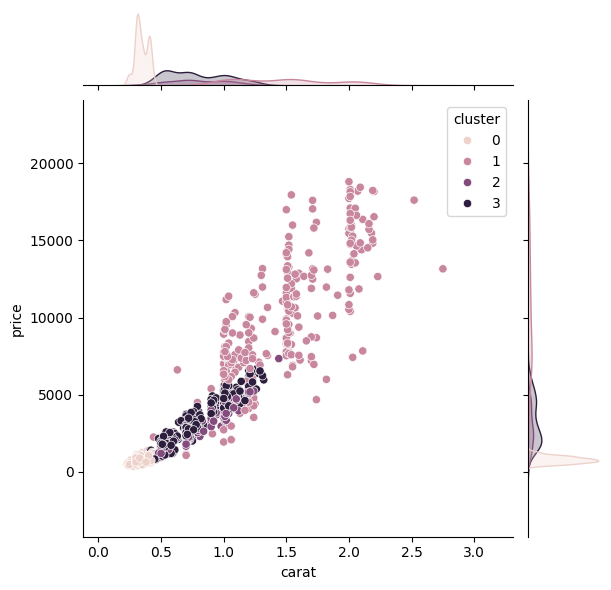

In [3]:
"""
Exercise 3 — Choosing the number of clusters with GMM + BIC (diamonds dataset)

This script:
1. Selects numeric variables (carat, depth, table, price) and cleans missing values.
2. Explores the distribution of price with mean and mean ± std lines.
3. Normalizes the numeric variables with StandardScaler.
4. Fits Gaussian Mixture Models with 1–8 components and plots BIC vs number of components.
5. Chooses the optimal number of components according to BIC and fits the final GMM.
6. Visualizes the resulting clusters with a pairplot and a jointplot (carat vs price).
"""

import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

def prepare_numeric_diamonds(df):
    """
    Selects numeric columns (carat, depth, table, price),
    checks for missing values, drops NaNs, and returns a clean dataframe.

    Args:
        df (DataFrame): Original diamonds dataframe.

    Returns:
        DataFrame: Clean numeric dataframe with selected columns.
    """
    diamonds_num = df[["carat", "depth", "table", "price"]]
    print("Missing values per column before dropna():")
    print(diamonds_num.isna().sum())
    diamonds_num = diamonds_num.dropna()
    print("\nMissing values per column after dropna():")
    print(diamonds_num.isna().sum())
    return diamonds_num

def plot_price_distribution(df):
    """
    Plots a histogram of price and draws vertical lines at
    mean and mean ± one standard deviation.

    Args:
        df (DataFrame): Numeric diamonds dataframe.
    """
    mean_price = df["price"].mean()
    std_price = df["price"].std()

    plt.figure(figsize=(8, 5))
    plt.hist(df["price"], bins=30, alpha=0.7, color="skyblue", edgecolor="black")
    plt.axvline(mean_price, color="red", linestyle="--", label="Mean")
    plt.axvline(mean_price + std_price, color="green", linestyle="--", label="Mean + 1 std")
    plt.axvline(mean_price - std_price, color="orange", linestyle="--", label="Mean - 1 std")
    plt.title("Price distribution with mean ± std")
    plt.xlabel("Price")
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()

def scale_diamonds(df):
    """
    Normalizes the numeric columns with StandardScaler.

    Args:
        df (DataFrame): Numeric diamonds dataframe.

    Returns:
        ndarray: Scaled numeric data.
    """
    scaler = StandardScaler()
    diamonds_scaled = scaler.fit_transform(df)
    return diamonds_scaled

def compute_bic_curve(X_scaled, n_components_range):
    """
    Fits GMM models for a range of component numbers and
    computes BIC for each.

    Args:
        X_scaled (ndarray): Scaled numeric data.
        n_components_range (range): Range of component counts.

    Returns:
        list: BIC values for each number of components.
    """
    bic = []
    for n in n_components_range:
        gmm = mixture.GaussianMixture(n_components=n, random_state=42)
        gmm.fit(X_scaled)
        bic.append(gmm.bic(X_scaled))
    return bic

def fit_best_gmm(X_scaled, bic, n_components_range):
    """
    Finds the number of components that minimizes BIC,
    fits the final GMM, and returns labels and best_n.

    Args:
        X_scaled (ndarray): Scaled numeric data.
        bic (list): BIC values.
        n_components_range (range): Range of component counts.

    Returns:
        int: Best number of components.
        ndarray: Cluster labels from the best GMM.
    """
    best_index = np.argmin(bic)
    best_n = n_components_range[best_index]
    print("Best number of components according to BIC:", best_n)

    best_gmm = mixture.GaussianMixture(n_components=best_n, random_state=42)
    best_gmm.fit(X_scaled)
    gmm_labels = best_gmm.predict(X_scaled)
    return best_n, gmm_labels

def plot_clustered_diamonds(df, labels):
    """
    Adds cluster labels to the unscaled numeric dataframe and
    creates a pairplot and a jointplot (carat vs price) colored by cluster.

    Args:
        df (DataFrame): Unscaled numeric diamonds dataframe.
        labels (ndarray): Cluster labels from GMM.
    """
    df_clustered = df.copy()
    df_clustered["cluster"] = labels

    sns.pairplot(df_clustered, vars=["carat", "depth", "table", "price"], hue="cluster", corner=True)
    plt.show()

    sns.jointplot(data=df_clustered, x="carat", y="price", hue="cluster", kind="scatter")
    plt.show()

# a) select numeric columns into diamonds_num, check missing values, dropna() and confirm it's clean
diamonds_num = prepare_numeric_diamonds(diamonds)

# b) histogram of 'price' with mean and mean +/- std lines
plot_price_distribution(diamonds_num)

# c) normalize the 4 numeric columns with StandardScaler
diamonds_scaled = scale_diamonds(diamonds_num)

# d) fit GMM for n_components = 1..8 on diamonds_scaled, store BIC values, plot BIC vs n_components
bic = []
n_components_range = range(1, 9)

bic = compute_bic_curve(diamonds_scaled, n_components_range)

plt.figure(figsize=(8, 5))
plt.plot(list(n_components_range), bic, marker="o")
plt.xlabel("Number of components")
plt.ylabel("BIC")
plt.title("BIC vs number of GMM components")
plt.show()

# e) find the number of components that minimizes BIC and fit the final GMM
best_n, gmm_labels = fit_best_gmm(diamonds_scaled, bic, n_components_range)

# f) add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)
plot_clustered_diamonds(diamonds_num, gmm_labels)

# g) Interpretation (to be written as markdown in the notebook, example):
# The BIC curve suggests an optimal number of clusters equal to `best_n`.
# In the pairplot, clusters separate mainly along carat and price, with some structure in depth/table.
# By eye, we might have guessed fewer or more clusters depending on how clearly separated the price bands look.
# Normalizing the data ensures that price does not dominate the clustering; without scaling, the optimal
# number of components could differ because the model would focus almost entirely on price variation.
